# Confocal RL vs RL-RbN

This notebook provides a example of confocal reconstruction with `RL-RbN`.

It compares:

- **Richardson–Lucy (RL)**: a conventional Poisson deconvolution of the full confocal image.
- **RL-RbN**: the same reconstruction principle applied to several independent photon realizations, with a consistency regularization across them.

The regularization parameter $\lambda$ is selected automatically with the **Poisson Residual Whiteness Principle (PRWP)**.

## 1. Imports

`brighteyes_ism` is used to read BrightEyes-MCS data and define the optical parameters,
`s2ism` is used for PSF calibration and the reference RL reconstruction,
`varreg` provides photon rebinning and RL-RbN.


In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import os

import brighteyes_ism.dataio.mcs as mcs
import brighteyes_ism.analysis.Graph_lib as gra
import brighteyes_ism.simulation.PSF_sim as psf_sim
import s2ism.psf_estimator as psf_est
from s2ism import s2ism as s2

from varreg import preprocessing as pp
from varreg import utils
from varreg import whiteness_principle as wp
from varreg import varreg

## 2. Settings

The optical values below are examples and should match the acquisition used in the notebook. If you use a different dataset, update the file path, wavelengths, and numerical aperture.

`N_REALIZATIONS` controls how many independent temporal photon realizations are built from the raw acquisition. The example uses **8**.


In [4]:
# ---- Data ----
wd_original = Path.cwd()
parts = list(wd_original.parts)
idx = next((i for i, p in enumerate(parts) if p.lower() == 'notebooks'), None)
wd = Path(*parts[:idx]) if idx is not None and idx > 0 else wd_original
DATA_PATH = os.path.join(wd, 'Data', 'Phalloidin_AF647_HeLa_PFA4_G0_2', 'Less_photons', '06_Phalloidin_AF647-23-06-2026-17-45-08.h5')


# ---- Microscope parameters ----
NA = 1.49
EXCITATION_NM = 639
EMISSION_NM = 671

# ---- Reference RL ----
RL_MAX_ITER = 500

# ---- RbN parameters ----
N_REALIZATIONS = 8
LAMBDA_GRID = np.linspace(5, 10, 5)
RBN_MAX_ITER = 2000

# ---- PRWP ----
PRWP_BORDER = 10

# Use CUDA when available. The varreg optimizer falls back to CPU automatically.
PROCESS = "gpu"


## 3. Load the BrightEyes-MCS acquisition

The expected raw layout is: `height × width × time bins × detector channels`


In [6]:
raw_data, metadata = mcs.load(DATA_PATH)
raw_data = np.asarray(raw_data).squeeze()

pixel_size_nm = metadata.dx * 1e3

print(f"Raw data shape: {raw_data.shape}")
print(f"Pixel size: {pixel_size_nm:.2f} nm")

Raw data shape: (601, 601, 64, 25)
Pixel size: 50.00 nm


## 4. Build the confocal image

A conventional confocal image is obtained by summing the acquisition over **time bins** and **detector channels**.

We also keep the detector-resolved image because it is useful for calibrating the PSF.


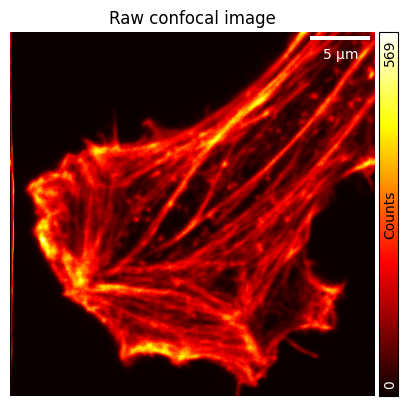

In [10]:
# Sum the temporal bins, but keep the detector channels for PSF calibration.
detector_image = raw_data.sum(axis=-2)          # (height, width, channels)

# Sum detector channels as well to obtain the conventional confocal image.
confocal_image = detector_image.sum(axis=-1)    # (height, width)

fig, ax = plt.subplots(figsize=(5, 5))
gra.ShowImg(confocal_image, pixel_size_nm * 1e-3, clabel='Counts', fig=fig, ax=ax)
ax.set_title("Raw confocal image")
plt.show()

## 5. Estimate the confocal PSF

The PSF describes how a point-like emitter is blurred by the microscope.

Here it is calibrated from the detector-array acquisition using the `s2ism` PSF-estimation tools. For the confocal reconstruction, the in-focus detector PSFs are summed over detector channels.


/home/lcuneo-iit.local/varreg/varreg/ISM_env/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


pxsizex       50.00
pxsizez       550.00
Nx            100.00
Nz            2.00
pxpitch       75000.00
pxdim         50000.00
pinhole_shape square
geometry      rect
N             5.00
M             488.00
rotation      4.97
mirroring     -1.00
name          
shift         70.81


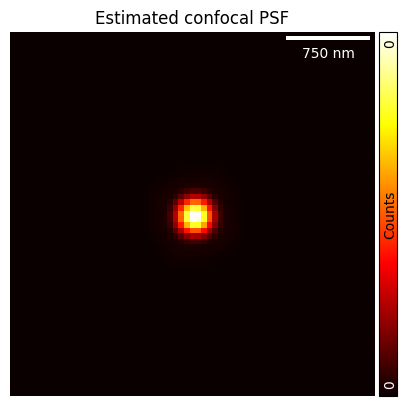

In [11]:
excitation = psf_sim.simSettings()
excitation.na = NA
excitation.wl = EXCITATION_NM
excitation.mask_sampl = 101

emission = excitation.copy()
emission.wl = EMISSION_NM

grid = psf_sim.GridParameters()
grid.pxsizex = pixel_size_nm
grid.Nz = 2

# Estimate the out-of-focus distance from the PSF parameters.
z_out_of_focus, _ = psf_est.find_out_of_focus_from_param(
    grid.pxsizex,
    excitation,
    emission,
    mode="Pearson",
    stack="positive",
    graph=False,
)
grid.pxsizez = z_out_of_focus

# Estimate the PSF from the detector image.
psf_ism, _, _ = psf_est.psf_estimator_from_data(
    detector_image,
    excitation,
    emission,
    grid,
    z_out_of_focus=z_out_of_focus,
)

# psf_ism[1] is the in-focus detector-resolved PSF stack.
confocal_psf = psf_ism[1].sum(axis=-1)
confocal_psf = confocal_psf / confocal_psf.sum()

fig, ax = plt.subplots(figsize=(5, 5))
gra.ShowImg(confocal_psf, pixel_size_nm * 1e-3, clabel='Counts', fig=fig, ax=ax)
ax.set_title("Estimated confocal PSF")
plt.show()

## 6. Create independent photon realizations

RL-RbN needs several statistically independent measurements of the same object.

BrightEyes-MCS acquisitions contain a temporal photon dimension, so we can obtain the realizations by grouping non-overlapping time bins. Each realization is built from a different part of the measured photon stream.

In [12]:
n_time_bins = raw_data.shape[-2]
if n_time_bins % N_REALIZATIONS != 0:
    raise ValueError(
        f"The acquisition contains {n_time_bins} time bins, which cannot be divided "
        f"exactly into {N_REALIZATIONS} realizations. Choose another N_REALIZATIONS."
    )

bins_per_realization = n_time_bins // N_REALIZATIONS

# Move time to the last axis: (height, width, channels, time bins).
time_last = np.moveaxis(raw_data, -2, -1)

# Rebin time into K independent realizations.
detector_realizations = pp.rebin(
    time_last,
    nbin=N_REALIZATIONS,
    length=bins_per_realization,
    channel=-1,
)

# Confocal case: sum the detector channels.
confocal_realizations = detector_realizations.sum(axis=-2)  # (height, width, K)

print(f"RL-RbN dataset shape: {confocal_realizations.shape}")
print(
    "Photon sum preserved:",
    np.allclose(confocal_realizations.sum(axis=-1), confocal_image),
)

RL-RbN dataset shape: (601, 601, 8)
Photon sum preserved: True


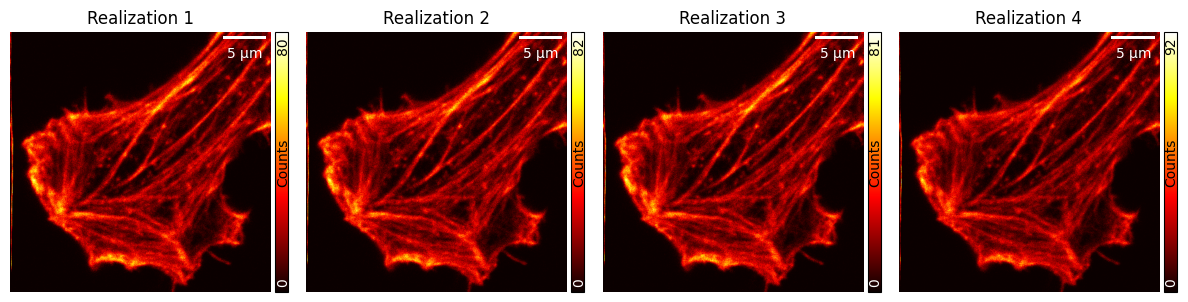

In [ ]:
# Show a few independent realizations.
n_show = min(4, N_REALIZATIONS)
fig, axes = plt.subplots(1, n_show, figsize=(3 * n_show, 3))
axes = np.atleast_1d(axes)

for k, ax in enumerate(axes):
    image_k = confocal_realizations[..., k]
    gra.ShowImg(image_k, pixel_size_nm * 1e-3, clabel='Counts', fig=fig, ax=ax)
    ax.set_title(f"Realization {k + 1}")

plt.tight_layout()
plt.show()

## 7. Optional spatial weight

RbN can use a spatial weight so that the consistency penalty adapts to the local signal-to-noise ratio.

To use a uniform weight everywhere define weight_map = 1

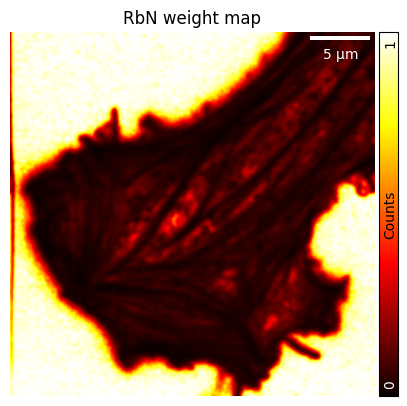

In [16]:
WEIGHT_SMOOTH_SIGMA = 2

weight_map = utils.calculate_weight_map(
    confocal_realizations,
    smooth_sigma=WEIGHT_SMOOTH_SIGMA,
    normalize=True)[..., 0]  # the same 2D weight is used for every realization

fig, ax = plt.subplots(figsize=(5, 5))
gra.ShowImg(weight_map, pixel_size_nm * 1e-3, clabel='Counts', fig=fig, ax=ax)
ax.set_title("RbN weight map")
plt.show()


## 8. Conventional Richardson–Lucy reconstruction

This is the reference reconstruction obtained from the confocal image.


In [19]:
RL_MAX_ITER = 5

rl_history, *_ = s2.max_likelihood_reconstruction(
    confocal_image[..., np.newaxis],
    confocal_psf[np.newaxis, ..., np.newaxis],
    max_iter=RL_MAX_ITER,
    rep_to_save="last",
)

rl_image = np.asarray(rl_history).squeeze()
print(f"RL reconstruction completed ({RL_MAX_ITER} iterations).")

The algorithm will run on the GPU.


Progress: 6it [00:00, 812.56it/s]              

RL reconstruction completed (5 iterations).


## 9. RL-RbN with automatic $\lambda$ selection

For each candidate $\lambda$, RL-RbN reconstructs the independent photon realizations jointly. PRWP then measures how noise-like the residual is and selects the candidate with the lowest whiteness value.


In [20]:
rbn_solver = wp.make_variance_reconstructor(
    dset=confocal_realizations,
    psf=confocal_psf,
    weight_map=weight_map,
    stop_tol=1e-8,
    stop_criteria="step_size",
    max_iter=RBN_MAX_ITER,
    method="sgp",
    regularizer_norm="l2",
    initialization="flat",
    normalize=True,
    process=PROCESS,
    rec_to_save="last",
    step_size_search="line_search",
    line_search_params=(1e18, 2),
    verbose=False,
)

prwp_device = torch.device("cuda" if PROCESS == "gpu" and torch.cuda.is_available() else "cpu")

best_lambda, best_obj, best_whiteness = wp.choose_lambda_by_WP(
    solver_fn=rbn_solver,
    lambdas=LAMBDA_GRID,
    dset=torch.as_tensor(confocal_realizations, dtype=torch.float32),
    psf=torch.as_tensor(confocal_psf, dtype=torch.float32),
    masked=True,
    remove_border=PRWP_BORDER,
    idx_in_focus=0,
    device=prwp_device,
    verbose=True,
)

# Sum the K realization-specific reconstructions to recover the full photon flux.
rbn_image = best_obj.sum(dim=-1).squeeze().numpy()

print(f"Selected lambda: {best_lambda:.4g}")
print(f"Residual whiteness: {best_whiteness:.6g}")

Using device: cuda
1/5: Testing lambda=5.0


sgp: 100%|██████████| 2000/2000 [00:05<00:00, 370.06it/s]


  Whiteness=16.132526
2/5: Testing lambda=6.25


sgp: 100%|██████████| 2000/2000 [00:05<00:00, 367.96it/s]


  Whiteness=16.1738
3/5: Testing lambda=7.5


sgp: 100%|██████████| 2000/2000 [00:06<00:00, 331.55it/s]


  Whiteness=16.208209
4/5: Testing lambda=8.75


sgp: 100%|██████████| 2000/2000 [00:05<00:00, 362.93it/s]


  Whiteness=16.245377
5/5: Testing lambda=10.0


sgp: 100%|██████████| 2000/2000 [00:05<00:00, 367.36it/s]

  Whiteness=16.220562
Selected lambda: 5
Residual whiteness: 16.1325


## 9b. RL-RbN with fixed $\lambda$

Run the following cell if you want to use a different preselected $\lambda$


In [ ]:
lambda_value = 1
rbn_image = varreg.variance_reconstruction(torch.as_tensor(confocal_realizations, dtype=torch.float32),
                               torch.as_tensor(confocal_psf, dtype=torch.float32),
                                lambda_value=lambda_value,  weight_map=weight_map,
                                max_iter=RBN_MAX_ITER, stop_tol=1e-8, stop_criteria="step_size", method="sgp",
                                regularizer_norm="l2", initialization="flat", normalize=True,
                                process='gpu', rec_to_save='last', step_size_search="line_search",
                                line_search_params=(1e18, 2), verbose=False)

## 10. Compare the results

The three panels show the measured confocal image, conventional RL, and RL-RbN.

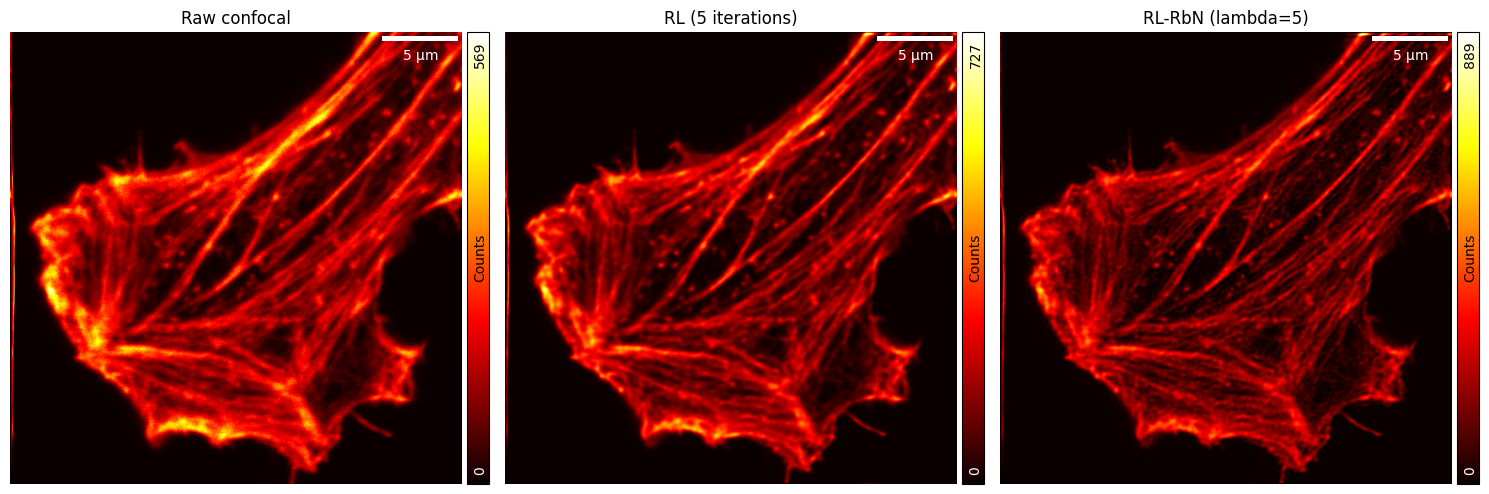

In [21]:
images = [confocal_image, rl_image, rbn_image]
titles = ["Raw confocal", f"RL ({RL_MAX_ITER} iterations)", f"RL-RbN (lambda={best_lambda:.3g})"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, image, title in zip(axes, images, titles):
    vmax = np.percentile(image, 99.9)
    gra.ShowImg(image, pixel_size_nm * 1e-3, clabel='Counts', fig=fig, ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

## 11. Optional: save the results

Uncomment the cell below if you want to save the three images and the selected regularization parameter in a compact NumPy file.


In [ ]:
# OUTPUT_PATH = Path("results/confocal_rl_vs_rbn.npz")
# OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
#
# np.savez(
#     OUTPUT_PATH,
#     raw_confocal=confocal_image,
#     rl=rl_image,
#     rl_rbn=rbn_image,
#     best_lambda=best_lambda,
#     best_whiteness=best_whiteness,
# )
#
# print(f"Saved to: {OUTPUT_PATH}")